In [ ]:
%pip install pandas matplotlib scikit-learn

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import json
import shutil
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
OUT = Path("ml15_pair1")
OUT.mkdir(exist_ok=True)
LABELS = ["normal", "suspicious"]
POSITIVE = "suspicious"
print("Class order:", LABELS, "Positive class:", POSITIVE)
print("scikit-learn:", sklearn.__version__)

Class order: ['normal', 'suspicious'] Positive class: suspicious
scikit-learn: 1.6.1


In [ ]:
toy = pd.DataFrame({
 "actual": ["normal"]*4 + ["suspicious"]*4,
 "predicted": ["normal", "normal", "suspicious", "normal",
 "normal", "suspicious", "suspicious", "normal"],
}, index=[f"R{i}" for i in range(1, 9)])
toy.index.name = "record_id"
toy["correct"] = toy["actual"] == toy["predicted"]
manual_correct = int(toy["correct"].sum())
manual_accuracy = manual_correct / len(toy)
assert manual_correct == 5 and manual_accuracy == 0.625
print(toy)
print("Correct:", manual_correct, "/", len(toy), "Accuracy:", manual_accuracy)

               actual   predicted  correct
record_id                                 
R1             normal      normal     True
R2             normal      normal     True
R3             normal  suspicious    False
R4             normal      normal     True
R5         suspicious      normal    False
R6         suspicious  suspicious     True
R7         suspicious  suspicious     True
R8         suspicious      normal    False
Correct: 5 / 8 Accuracy: 0.625


In [ ]:
actual = toy["actual"]
predicted = toy["predicted"]
toy_tn = int(((actual == "normal") & (predicted == "normal")).sum())
toy_fp = int(((actual == "normal") & (predicted == "suspicious")).sum())
toy_fn = int(((actual == "suspicious") & (predicted == "normal")).sum())
toy_tp = int(((actual == "suspicious") & (predicted == "suspicious")).sum())
assert (toy_tn, toy_fp, toy_fn, toy_tp) == (3, 1, 2, 2)
assert toy_tn + toy_fp + toy_fn + toy_tp == len(toy)
print("TN FP FN TP:", toy_tn, toy_fp, toy_fn, toy_tp)

TN FP FN TP: 3 1 2 2


In [ ]:
toy_cm = confusion_matrix(toy["actual"], toy["predicted"], labels=LABELS)
toy_accuracy = accuracy_score(toy["actual"], toy["predicted"])
assert np.array_equal(toy_cm, [[3, 1], [2, 2]])
assert np.isclose(toy_accuracy, manual_accuracy)
assert np.isclose(np.trace(toy_cm)/toy_cm.sum(), toy_accuracy)
toy_matrix_table = pd.DataFrame(toy_cm, index=LABELS, columns=LABELS)
toy_matrix_table.index.name = "actual_label"
toy_matrix_table.columns.name = "predicted_label"
print(toy_matrix_table)
print("Accuracy from diagonal:", np.trace(toy_cm)/toy_cm.sum())

predicted_label  normal  suspicious
actual_label                       
normal                3           1
suspicious            2           2
Accuracy from diagonal: 0.625


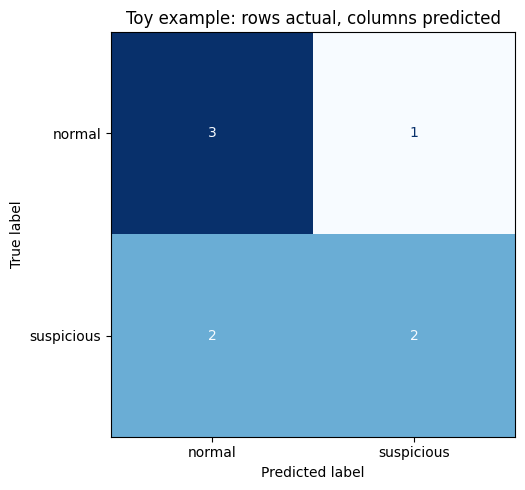

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(toy_cm, display_labels=LABELS).plot(ax=ax, cmap="Blues",
colorbar=False)
ax.set_title("Toy example: rows actual, columns predicted")
fig.tight_layout()
fig.savefig(OUT / "01_toy_matrix.png", dpi=150)
plt.show()

In [ ]:
swapped_arguments = confusion_matrix(toy["predicted"], toy["actual"],
labels=LABELS)
reversed_labels = confusion_matrix(toy["actual"], toy["predicted"],
labels=LABELS[::-1])
assert np.array_equal(swapped_arguments, toy_cm.T)
assert np.array_equal(reversed_labels, toy_cm[::-1, ::-1])
assert np.isclose(accuracy_score(toy["predicted"], toy["actual"]), toy_accuracy)
print("Wrong argument order for our intended axes:\n", swapped_arguments)
print("Explicit reversed class order:\n", reversed_labels)

Wrong argument order for our intended axes:
 [[3 2]
 [1 2]]
Explicit reversed class order:
 [[2 2]
 [1 3]]


In [ ]:
toy_normalized = confusion_matrix(toy["actual"], toy["predicted"], labels=LABELS,
normalize="true")
manual_normalized = toy_cm / toy_cm.sum(axis=1, keepdims=True)
assert np.allclose(toy_normalized, manual_normalized)
assert np.allclose(toy_normalized, [[0.75, 0.25], [0.5, 0.5]])
print(pd.DataFrame(toy_normalized, index=LABELS, columns=LABELS))


            normal  suspicious
normal        0.75        0.25
suspicious    0.50        0.50


In [ ]:
DATA_SEED, SPLIT_SEED = 12, 42
N_PER_CLASS = 120
rng = np.random.default_rng(DATA_SEED)
normal = pd.DataFrame({
 "packets_per_min": np.clip(np.rint(rng.normal(500, 190, N_PER_CLASS)), 1,
None).astype(int),
 "failed_logins": rng.poisson(1.0, N_PER_CLASS),
 "unique_ports": rng.poisson(3.0, N_PER_CLASS)+1, "label": "normal",
})
suspicious = pd.DataFrame({
 "packets_per_min": np.clip(np.rint(rng.normal(620, 230, N_PER_CLASS)), 1,
None).astype(int),
 "failed_logins": rng.poisson(4.0, N_PER_CLASS),
 "unique_ports": rng.poisson(8.0, N_PER_CLASS)+1, "label": "suspicious",
})
df = pd.concat([normal, suspicious], ignore_index=True)
df = df.sample(frac=1, random_state=DATA_SEED).reset_index(drop=True)
df.index.name = "record_id"
df_snapshot = df.copy(deep=True)
features = ["packets_per_min", "failed_logins", "unique_ports"]
assert df.shape == (240, 4) and df.index.is_unique
assert not df.isna().any().any() and (df[features] >= 0).all().all()
print(df.head())
print(df["label"].value_counts())

           packets_per_min  failed_logins  unique_ports       label
record_id                                                          
0                      327              0             3      normal
1                      361              0             5      normal
2                      895              1             6      normal
3                      586              3             1      normal
4                      815              2             7  suspicious
label
normal        120
suspicious    120
Name: count, dtype: int64


In [ ]:
X, y = df[features].copy(), df["label"].copy()
X_dev, X_test, y_dev, y_test = train_test_split(
 X, y, test_size=0.25, random_state=SPLIT_SEED, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
 X_dev, y_dev, test_size=0.25, random_state=SPLIT_SEED, stratify=y_dev)
assert (len(X_train), len(X_val), len(X_test)) == (135, 45, 60)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_dev.index).isdisjoint(X_test.index)
assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)
assert X_test.index.equals(y_test.index)
assert "label" not in X.columns and "record_id" not in X.columns
print("Train / validation / test:", len(X_train), len(X_val), len(X_test))

Train / validation / test: 135 45 60


In [ ]:
def make_model(C):
 return Pipeline([("scale", StandardScaler()),
 ("logreg", LogisticRegression(C=C, solver="lbfgs",
max_iter=2000))])
candidates, candidate_rows = {}, []
for C in [0.01, 0.1, 1.0, 10.0, 100.0]:
 model = make_model(C)
 model.fit(X_train, y_train)
 candidates[C] = model
 candidate_rows.append({"C": C, "train_accuracy": model.score(X_train, y_train),
 "validation_accuracy": model.score(X_val, y_val)})
candidate_table = pd.DataFrame(candidate_rows)
ranked = candidate_table.sort_values(["validation_accuracy", "C"], ascending=
[False, True])
chosen_C = float(ranked.iloc[0]["C"])
validation_model = candidates[chosen_C]
assert int(validation_model.named_steps["scale"].n_samples_seen_) == 135
assert np.allclose(validation_model.named_steps["scale"].mean_,
X_train.mean().to_numpy())
print(candidate_table.round(4).to_string(index=False))
print("Chosen C:", chosen_C)

     C  train_accuracy  validation_accuracy
  0.01          0.9556               0.9333
  0.10          0.9556               0.9333
  1.00          0.9556               0.9333
 10.00          0.9333               0.9333
100.00          0.9333               0.9333
Chosen C: 0.01


 threshold  n  accuracy  TN  FP  FN  TP
       0.3 45    0.5111   1  22   0  22
       0.5 45    0.9333  22   1   2  20
       0.7 45    0.6667  23   0  15   7


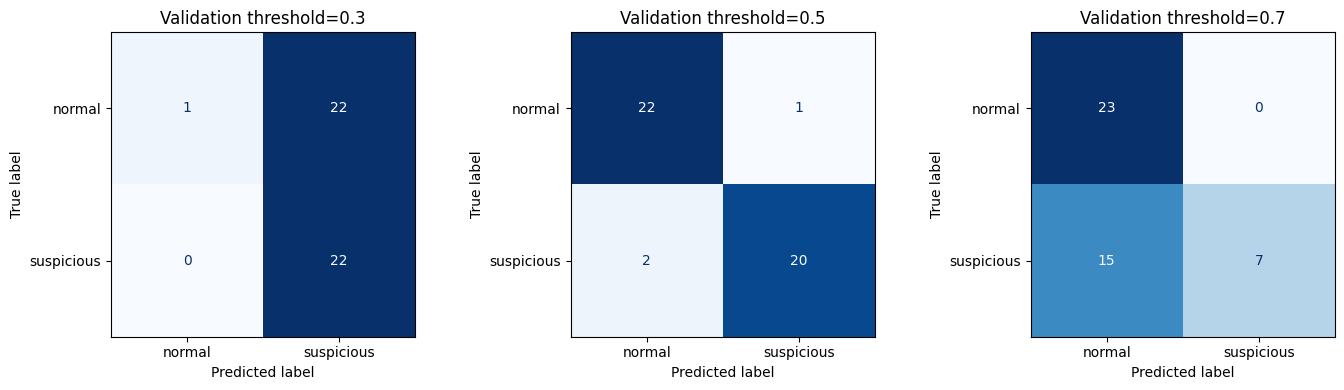

In [ ]:
def audit_predictions(y_true, y_pred):
    actual = np.asarray(y_true)
    predicted = np.asarray(y_pred)
    if actual.ndim != 1 or predicted.ndim != 1 or len(actual) == 0 or len(actual) != len(predicted):
      raise ValueError("Use two equally sized nonempty one-dimensional label arrays.")
    if not set(actual).issubset(LABELS) or not set(predicted).issubset(LABELS):
      raise ValueError("Unexpected class name.")
    matrix = confusion_matrix(actual, predicted, labels=LABELS)
    tn, fp, fn, tp = map(int, matrix.ravel())
    accuracy = float(accuracy_score(actual, predicted))
    assert matrix.sum() == len(actual)
    assert np.isclose(accuracy, (tn+tp)/len(actual))
    report = {"n": len(actual), "accuracy": accuracy,"TN": tn, "FP": fp, "FN": fn, "TP": tp}
    return matrix, report


val_classes = list(validation_model.classes_)
positive_column = val_classes.index(POSITIVE)
val_p = validation_model.predict_proba(X_val)[:, positive_column]
threshold_rows, threshold_matrices = [], []
for threshold in [0.3, 0.5, 0.7]:
  answers = np.where(val_p >= threshold, "suspicious", "normal")
  matrix, report = audit_predictions(y_val, answers)
  threshold_rows.append({"threshold": threshold, **report})
  threshold_matrices.append(matrix)
threshold_table = pd.DataFrame(threshold_rows)
print(threshold_table.round(4).to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, threshold, matrix in zip(axes, [0.3, 0.5, 0.7], threshold_matrices):
 ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(ax=ax, cmap="Blues",
colorbar=False)
 ax.set_title(f"Validation threshold={threshold}")
fig.tight_layout()
fig.savefig(OUT / "02_validation_thresholds.png", dpi=150)
plt.show()

In [ ]:
final_model = make_model(chosen_C)
final_model.fit(X_dev, y_dev)
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_dev, y_dev)
assert int(final_model.named_steps["scale"].n_samples_seen_) == 180
assert np.allclose(final_model.named_steps["scale"].mean_, X_dev.mean().to_numpy())
assert set(X_dev.index).isdisjoint(X_test.index)
final_classes = list(final_model.classes_)
final_positive_column = final_classes.index(POSITIVE)
print("Final fit rows: 180; C:", chosen_C)

Final fit rows: 180; C: 0.01


In [ ]:
test_prediction = final_model.predict(X_test)
test_probability = final_model.predict_proba(X_test)[:, final_positive_column]
test_cm, test_report = audit_predictions(y_test, test_prediction)
test_correct = int(np.count_nonzero(y_test.to_numpy() == test_prediction))
accuracy_manual = test_correct/len(y_test)
accuracy_from_matrix = float(np.trace(test_cm)/test_cm.sum())
assert np.isclose(accuracy_manual, test_report["accuracy"])
assert np.isclose(accuracy_from_matrix, test_report["accuracy"])
print("Correct:", test_correct, "/", len(y_test))
print("Manual / library / matrix:", accuracy_manual, test_report["accuracy"],
accuracy_from_matrix)

Correct: 53 / 60
Manual / library / matrix: 0.8833333333333333 0.8833333333333333 0.8833333333333333


In [ ]:
test_matrix_table = pd.DataFrame(test_cm, index=LABELS, columns=LABELS)
test_matrix_table.index.name = "actual_label"
test_matrix_table.columns.name = "predicted_label"
print(test_matrix_table)
print(test_report)
assert np.array_equal(test_cm.sum(axis=1), y_test.value_counts().reindex(LABELS,
fill_value=0).to_numpy())
assert np.array_equal(test_cm.sum(axis=0),
pd.Series(test_prediction).value_counts().reindex(LABELS, fill_value=0).to_numpy())

predicted_label  normal  suspicious
actual_label                       
normal               27           3
suspicious            4          26
{'n': 60, 'accuracy': 0.8833333333333333, 'TN': 27, 'FP': 3, 'FN': 4, 'TP': 26}


In [ ]:
test_results = X_test.copy()
test_results["actual"] = y_test
test_results["predicted"] = test_prediction
test_results["p_suspicious"] = test_probability
conditions = [
 (test_results["actual"] == "normal") & (test_results["predicted"] == "normal"),
  (test_results["actual"] == "normal") & (test_results["predicted"] =="suspicious"),
   (test_results["actual"] == "suspicious") & (test_results["predicted"] =="normal"),
    (test_results["actual"] == "suspicious") & (test_results["predicted"] =="suspicious"),
]
test_results["outcome"] = np.select(conditions, ["TN", "FP", "FN", "TP"],
default="INVALID")
assert "INVALID" not in set(test_results["outcome"])
for outcome in ["TN", "FP", "FN", "TP"]:
 assert int((test_results["outcome"] == outcome).sum()) == test_report[outcome]
false_alarm_rows = test_results.loc[test_results["outcome"] == "FP"].copy()
missed_rows = test_results.loc[test_results["outcome"] == "FN"].copy()
assert len(false_alarm_rows)+len(missed_rows) == len(y_test)-test_correct
print("False alarms:\n", false_alarm_rows.round(4))
print("Missed suspicious:\n", missed_rows.round(4))

False alarms:
            packets_per_min  failed_logins  unique_ports  actual   predicted  \
record_id                                                                     
152                    435              2             8  normal  suspicious   
230                    605              3             6  normal  suspicious   
200                    628              2             7  normal  suspicious   

           p_suspicious outcome  
record_id                        
152              0.5058      FP  
230              0.5164      FP  
200              0.5098      FP  
Missed suspicious:
            packets_per_min  failed_logins  unique_ports      actual predicted  \
record_id                                                                       
202                    401              2             7  suspicious    normal   
207                    955              2             4  suspicious    normal   
209                    220              4             5  suspicious    norm

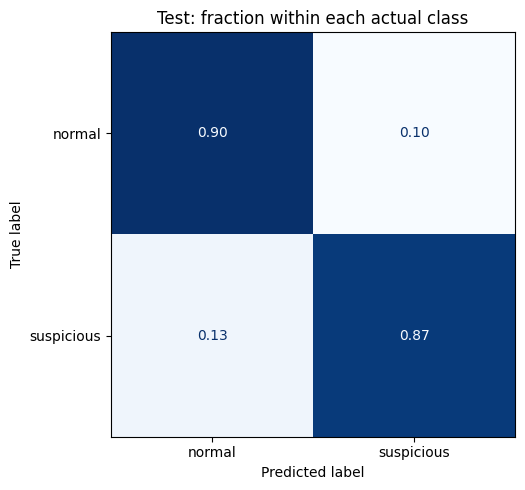

predicted_label  normal  suspicious
actual_label                       
normal           0.9000      0.1000
suspicious       0.1333      0.8667


In [ ]:
test_cm_normalized = confusion_matrix(y_test, test_prediction, labels=LABELS,
normalize="true")
assert np.allclose(test_cm_normalized.sum(axis=1), 1)
test_normalized_table = pd.DataFrame(test_cm_normalized, index=LABELS,
columns=LABELS)
test_normalized_table.index.name = "actual_label"
test_normalized_table.columns.name = "predicted_label"
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(test_cm_normalized, display_labels=LABELS).plot(
 ax=ax, cmap="Blues", colorbar=False, values_format=".2f")
ax.set_title("Test: fraction within each actual class")
fig.tight_layout()
fig.savefig(OUT / "04_test_row_normalized.png", dpi=150)
plt.show()
print(test_normalized_table.round(4))

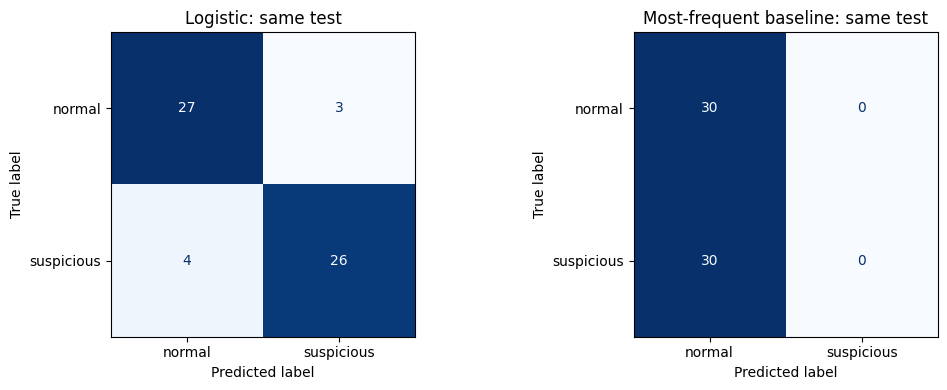

Logistic: {'n': 60, 'accuracy': 0.8833333333333333, 'TN': 27, 'FP': 3, 'FN': 4, 'TP': 26}
Baseline: {'n': 60, 'accuracy': 0.5, 'TN': 30, 'FP': 0, 'FN': 30, 'TP': 0}


In [ ]:
baseline_prediction = baseline.predict(X_test)
baseline_cm, baseline_report = audit_predictions(y_test, baseline_prediction)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, matrix, title in zip(axes, [test_cm, baseline_cm], ["Logistic: same test",
"Most-frequent baseline: same test"]):
 ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(ax=ax, cmap="Blues",
colorbar=False)
 ax.set_title(title)
fig.tight_layout()
fig.savefig(OUT / "03_test_model_and_baseline.png", dpi=150)
plt.show()
print("Logistic:", test_report)
print("Baseline:", baseline_report)

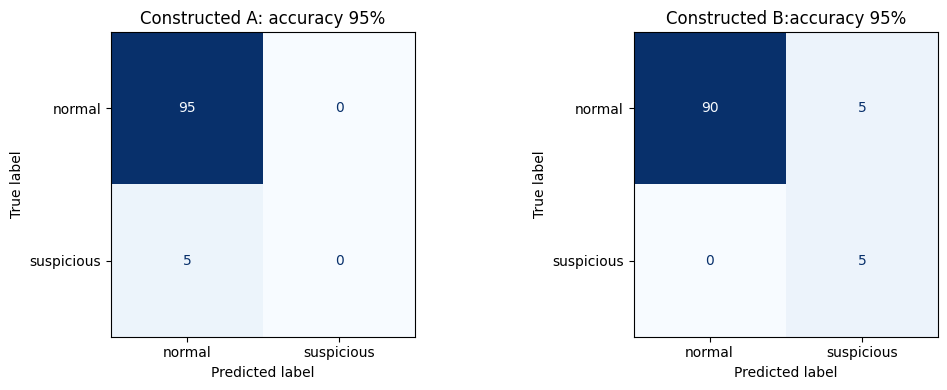

Constructed A: {'n': 100, 'accuracy': 0.95, 'TN': 95, 'FP': 0, 'FN': 5, 'TP': 0}
Constructed B: {'n': 100, 'accuracy': 0.95, 'TN': 90, 'FP': 5, 'FN': 0, 'TP': 5}


In [ ]:
imbalanced = pd.DataFrame({
 "actual": ["normal"]*95 + ["suspicious"]*5,
 "all_normal_prediction": ["normal"]*100,
 "alternative_prediction": ["normal"]*90 + ["suspicious"]*10,
})
imbalanced.index.name = "record_id"
imbalance_cm_a, imbalance_report_a = audit_predictions(imbalanced["actual"],
imbalanced["all_normal_prediction"])
imbalance_cm_b, imbalance_report_b = audit_predictions(imbalanced["actual"],
imbalanced["alternative_prediction"])
assert np.isclose(imbalance_report_a["accuracy"], 0.95)
assert np.isclose(imbalance_report_b["accuracy"], 0.95)
assert (imbalance_report_a["FN"], imbalance_report_a["TP"]) == (5, 0)
assert (imbalance_report_b["FP"], imbalance_report_b["FN"]) == (5, 0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, matrix, title in zip(axes, [imbalance_cm_a, imbalance_cm_b], ["Constructed A: accuracy 95%", "Constructed B:accuracy 95%"]):
  ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(ax=ax, cmap="Blues",colorbar=False)
  ax.set_title(title)
fig.tight_layout()
fig.savefig(OUT / "05_same_accuracy_different_errors.png", dpi=150)
plt.show()
print("Constructed A:", imbalance_report_a)
print("Constructed B:", imbalance_report_b)


In [ ]:
single_actual = ["normal"]*4
single_prediction = ["normal"]*4
single_cm, single_report = audit_predictions(single_actual, single_prediction)
assert single_cm.shape == (2, 2)
assert np.array_equal(single_cm, [[4, 0], [0, 0]])
single_normalized = confusion_matrix(single_actual, single_prediction,
labels=LABELS, normalize="true")
print("Missing suspicious class:\n", single_cm)
print("Normalized display:\n", single_normalized)
try:
 audit_predictions([], [])
except ValueError as error:
 print("Empty input rejected:", error)
else:
 raise AssertionError("Empty input was not rejected.")

Missing suspicious class:
 [[4 0]
 [0 0]]
Normalized display:
 [[1. 0.]
 [0. 0.]]
Empty input rejected: Use two equally sized nonempty one-dimensional label arrays.


In [ ]:
split_assignment = pd.concat([pd.Series("train", index=X_train.index),pd.Series("validation", index=X_val.index),pd.Series("test",index=X_test.index)]).rename("split")
split_manifest = df[["label"]].join(split_assignment).sort_index()
assert not split_manifest.isna().any().any()
summary_metrics = pd.DataFrame([
    {"source": "network_test", "prediction_source": "LogisticRegression",
     **test_report},
    {"source": "network_test", "prediction_source": "most_frequent_baseline",
     **baseline_report},
    {"source": "constructed_imbalanced", "prediction_source": "all_normal",
     **imbalance_report_a},
    {"source": "constructed_imbalanced", "prediction_source":
     "constructed_alternative", **imbalance_report_b},
])
tables = {"toy_predictions.csv": toy, "dataset.csv": df, "split_manifest.csv":
          split_manifest,"C_validation.csv": candidate_table, "test_predictions.csv":
          test_results,"test_confusion.csv": test_matrix_table,
          "test_confusion_row_normalized.csv": test_normalized_table,
          "validation_thresholds.csv": threshold_table,
          "imbalanced_predictions.csv": imbalanced, "summary_metrics.csv":
summary_metrics}
for name, table in tables.items():
  if table.index.name is None:
    table.index.name = "row_id"
    table.to_csv(OUT / name, encoding="utf-8-sig", index=True)
    restored = pd.read_csv(OUT / name, encoding="utf-8-sig", index_col=0)
    restored.columns.name = table.columns.name
  pd.testing.assert_frame_equal(table, restored, check_dtype= False check_exact=False, rtol=1e-10, atol=1e-10)
pd.testing.assert_frame_equal(df, df_snapshot)
print("Verified CSV rows:", {name: len(table) for name, table in tables.items()})

SyntaxError: invalid syntax. Perhaps you forgot a comma? (1509836953.py, line 27)